# MODULE 6 — POS Tagging, Named Entity Recognition & HMM–Viterbi

**Natural Language Processing · Phenikaa University**  
**Jupyter Notebook | Demo + Guided Practice + Exercises**

**Mục đích:** từ một chuỗi token $X=(x_1,\ldots,x_T)$, dự đoán chuỗi nhãn $Y=(y_1,\ldots,y_T)$ cho bài toán **POS** và **NER**; xây dựng và kiểm tra mô hình **Hidden Markov Model (HMM)** và thuật toán **Viterbi**.

> Notebook sử dụng dữ liệu ví dụ **tự tạo, dung lượng nhỏ** để chạy offline. Phần cuối có hướng dẫn đưa các tập dữ liệu `NER.csv`, `vi_train.txt`, `vi_test.txt` vào bài thực hành Lab 7. Những kết quả tính trên dữ liệu mẫu **không đại diện** cho chất lượng trên corpus thực tế.

## Kết quả học tập

Sau khi hoàn thành, sinh viên có thể:

1. Phân biệt **POS**, **NER** và **sequence labeling**; giải thích bộ nhãn UPOS và BIO.
2. Diễn giải các tham số $\pi$, $A$, $B$ của HMM; tính xác suất từ số đếm và smoothing.
3. Tự tính, viết code và kiểm tra thuật toán **Viterbi**.
4. Huấn luyện HMM supervised từ một corpus nhỏ, xử lý token ngoài từ vựng (**OOV**).
5. Đánh giá **POS token accuracy** và **NER entity-level precision/recall/F1**; phân tích vấn đề tách từ tiếng Việt.

| Phần | Hoạt động | Thời lượng gợi ý |
|---|---|---:|
| A | Sequence labeling, POS và BIO | 20 phút |
| B | Demo HMM và Viterbi tính tay | 30 phút |
| C | Huấn luyện HMM, POS tiếng Việt | 35 phút |
| D | NER, BIO, đánh giá theo span | 35 phút |
| E | Thực hành nâng cao và bài tập | 60–90 phút |

**Cách dùng:** chạy các ô từ trên xuống; các ô `TODO` ở cuối là nhiệm vụ cho sinh viên, chưa hoàn thiện vẫn không chặn thao tác *Run all*.

### Chuẩn bị môi trường

- Chạy được trên **Google Colab** hoặc Jupyter Notebook có Python 3.
- Dùng chủ yếu thư viện chuẩn Python; `pandas` và `matplotlib` để hiển thị bảng và đồ thị.
- **Không yêu cầu tải dữ liệu hay mô hình từ Internet** ở phần demo.

Nếu môi trường chưa có `pandas` / `matplotlib`, chạy `!pip install pandas matplotlib` trong một ô mới.

In [1]:
from collections import Counter, defaultdict
from itertools import product
from dataclasses import dataclass, field
from pathlib import Path
import math, random, csv
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
print("Môi trường sẵn sàng | Python HMM lab | seed =", SEED)

Môi trường sẵn sàng | Python HMM lab | seed = 42


---
# PHẦN A · Sequence labeling, POS và NER

## A1. Bài toán gán nhãn chuỗi

Với chuỗi các token $X=(x_1,\dots,x_T)$ và tập nhãn $\mathcal{Y}$, mục tiêu là tìm:

$$
Y^* = \underset{Y\in\mathcal{Y}^T}{\arg\max}\; P(Y\mid X).
$$

- **POS tagging:** mỗi token nhận một nhãn từ loại như `NOUN`, `VERB`, `ADJ`, `PROPN`.
- **NER:** mỗi token nhận nhãn BIO như `B-PER`, `I-ORG`, `O`; kết quả cuối cùng là các **span thực thể**.
- Khác với phân loại văn bản, các nhãn trong cùng câu **không độc lập**.

**Chú ý tiếng Việt:** `sinh_viên`, `Hà_Nội` trong notebook là **token từ** (word segmentation đã thực hiện), không phải các tiếng tách bởi dấu cách trong văn bản thô.

In [2]:
pos_tokens = ["Tôi", "học", "tại", "Đại_học", "Phenikaa", "."]
pos_labels = ["PRON", "VERB", "ADP", "NOUN", "PROPN", "PUNCT"]
display(pd.DataFrame({"Token": pos_tokens, "POS (ví dụ minh họa)": pos_labels}))

,Token,POS (ví dụ minh họa)
0,Tôi,PRON
1,học,VERB
2,tại,ADP
3,Đại_học,NOUN
4,Phenikaa,PROPN
5,.,PUNCT


### A2. Bộ nhãn POS: UPOS và nhãn bản địa

**Universal POS (UPOS)** gồm 17 nhãn: `ADJ`, `ADP`, `ADV`, `AUX`, `CCONJ`, `DET`, `INTJ`, `NOUN`, `NUM`, `PART`, `PRON`, `PROPN`, `PUNCT`, `SCONJ`, `SYM`, `VERB`, `X`.

Không nhầm lẫn:
- **UPOS**: hệ nhãn phổ quát (ví dụ `NOUN`, `VERB`).
- **Nhãn POS của một corpus Việt cụ thể**: có thể dùng `N`, `V`, `Np`, `A`, ... với định nghĩa riêng.

**Nguyên tắc:** chỉ huấn luyện/đánh giá trên một tập dữ liệu khi **quy tắc tách từ** và **hệ thống nhãn** đã thống nhất. Không được mặc nhiên coi `N` là `NOUN`, hoặc `Np` là `PROPN` nếu chưa có bảng ánh xạ được kiểm chứng.

**Câu hỏi nhanh:** Trong hai ví dụ “chiếc **bàn** mới” và “chúng tôi **bàn** kế hoạch”, từ *bàn* mang cùng POS hay không?

In [3]:
contexts = [
    ("Tôi mua chiếc bàn mới .".split(), ["PRON", "VERB", "NOUN", "NOUN", "ADJ", "PUNCT"]),
    ("Chúng_tôi bàn kế_hoạch .".split(), ["PRON", "VERB", "NOUN", "PUNCT"]),
]
for toks, tags in contexts:
    print("  ".join(f"{w}/{y}" for w, y in zip(toks, tags)))

Tôi/PRON  mua/VERB  chiếc/NOUN  bàn/NOUN  mới/ADJ  ./PUNCT
Chúng_tôi/PRON  bàn/VERB  kế_hoạch/NOUN  ./PUNCT


## A3. NER dưới dạng BIO

**Loại thực thể ví dụ:** `PER` (người), `ORG` (tổ chức), `LOC` (địa điểm). Nhãn thực tế có thể có thêm `GPE`, `DATE`, `TIME`, ... tùy corpus.

- `B-X`: token **bắt đầu** thực thể loại X.
- `I-X`: token **tiếp theo** bên trong cùng thực thể loại X.
- `O`: ngoài mọi thực thể.

Nếu có $K$ loại thực thể, hệ nhãn BIO có $2K+1$ nhãn. **Ví dụ:** với `PER`, `ORG`, `LOC`, có $2\times3+1=7$ nhãn.

Trong BIO chuẩn, `I-ORG` không được xuất hiện ở đầu câu hoặc nối sau `B-PER`; phần D sẽ xử lý ràng buộc này.

In [4]:
ner_tokens = ["Nguyễn", "Văn", "An", "làm_việc", "tại", "Đại_học", "Phenikaa", "."]
ner_labels = ["B-PER", "I-PER", "I-PER", "O", "O", "B-ORG", "I-ORG", "O"]
display(pd.DataFrame({"Token": ner_tokens, "BIO tag": ner_labels}))

,Token,BIO tag
0,Nguyễn,B-PER
1,Văn,I-PER
2,An,I-PER
3,làm_việc,O
4,tại,O
5,Đại_học,B-ORG
6,Phenikaa,I-ORG
7,.,O


---
# PHẦN B · HMM và Viterbi — minh họa đúng ví dụ trong slide Module 6

## B1. Mô hình Markov ẩn (HMM)

Cho token $x_t$ (quan sát) và nhãn $y_t$ (trạng thái ẩn), HMM bậc 1 gồm:

- **Phân phối khởi tạo** $\pi_j=P(y_1=j)$.
- **Xác suất chuyển trạng thái** $a_{ij}=P(y_t=j\mid y_{t-1}=i)$.
- **Xác suất phát xạ** $b_j(x)=P(x_t=x\mid y_t=j)$.

Hai giả định chính:

$$
P(y_t\mid y_1,\ldots,y_{t-1})\approx P(y_t\mid y_{t-1}),
$$

$$
P(x_t\mid x_1,\ldots,x_{t-1},y_1,\ldots,y_t)\approx P(x_t\mid y_t).
$$

Xác suất chung (không xét trạng thái kết thúc) là:

$$
P(X,Y)=\pi_{y_1}b_{y_1}(x_1)\prod_{t=2}^{T}a_{y_{t-1},y_t}b_{y_t}(x_t).
$$

**HMM là mô hình sinh $P(X,Y)$**; khi giải mã, ta tìm $Y^*=\arg\max_Y P(X,Y)$, tương đương cực đại $P(Y\mid X)$ với cùng $X$.

## B2. Dữ liệu xác suất của ví dụ “sinh_viên học”

Đúng theo các **slide 26 và 34–37** của `Module6-Name Entity Recognition.pptx`:

- Trạng thái $\mathcal{Y}=\{N,V\}$.
- Quan sát $X=(\text{sinh\_viên},\text{học})$.
- $\pi(N)=0.8$, $\pi(V)=0.2$.
- Ma trận chuyển trạng thái $A$ và phát xạ $B$ như dưới đây.

**Lưu ý:** trong slide chỉ có hai cột phát xạ được liệt kê; đây là xác suất của **hai token cần thiết**, phần khối lượng còn lại thuộc những token khác. Để minh họa một phân phối hợp lệ trong code, ta thêm token `_OTHER_` (không dùng khi giải mã câu này).

In [5]:
states = ["N", "V"]
words = ["sinh_viên", "học"]
pi = {"N": 0.80, "V": 0.20}
A = {
    "N": {"N": 0.30, "V": 0.70},
    "V": {"N": 0.60, "V": 0.40},
}
B = {
    "N": {"sinh_viên": 0.70, "học": 0.20, "_OTHER_": 0.10},
    "V": {"sinh_viên": 0.10, "học": 0.60, "_OTHER_": 0.30},
}
print("π:", pi)
print("A (hàng: nhãn trước, cột: nhãn sau)")
display(pd.DataFrame(A).T)
print("B (hàng: nhãn, cột: quan sát)")
display(pd.DataFrame(B).T)
assert abs(sum(pi.values()) - 1) < 1e-12
assert all(abs(sum(row.values()) - 1) < 1e-12 for row in A.values())
assert all(abs(sum(row.values()) - 1) < 1e-12 for row in B.values())

π: {'N': 0.8, 'V': 0.2}
A (hàng: nhãn trước, cột: nhãn sau)


,N,V
N,0.3,0.7
V,0.6,0.4


B (hàng: nhãn, cột: quan sát)


,sinh_viên,học,_OTHER_
N,0.7,0.2,0.1
V,0.1,0.6,0.3


## B3. So sánh vét cạn với Viterbi

Nếu có $K$ nhãn và $T$ token, tìm kiếm mọi đường đi cần xét $K^T$ chuỗi.

Ta có thể dùng vét cạn để **kiểm thử với câu ngắn**; nhưng với văn bản dài, Viterbi giảm độ phức tạp về thời gian xuống $O(TK^2)$ cho HMM bậc 1.

In [6]:
def toy_joint_probability(tokens, labels, pi, A, B):
    """P(X,Y) trong ví dụ HMM nhỏ, không có trạng thái END."""
    p = pi[labels[0]] * B[labels[0]][tokens[0]]
    for t in range(1, len(tokens)):
        p *= A[labels[t-1]][labels[t]] * B[labels[t]][tokens[t]]
    return p

all_paths = []
for labels in product(states, repeat=len(words)):
    p = toy_joint_probability(words, labels, pi, A, B)
    all_paths.append({"Nhãn (Y)": " → ".join(labels), "P(X,Y)": p})
df_paths = pd.DataFrame(all_paths).sort_values("P(X,Y)", ascending=False)
display(df_paths)
print("Chuỗi nhãn tốt nhất:", df_paths.iloc[0]["Nhãn (Y)"], "| xác suất =", df_paths.iloc[0]["P(X,Y)"])

,Nhãn (Y),"P(X,Y)"
1,N → V,0.2352
0,N → N,0.0336
3,V → V,0.0048
2,V → N,0.0024


Chuỗi nhãn tốt nhất: N → V | xác suất = 0.23519999999999996


## B4. Viterbi: quy hoạch động

Ký hiệu $\delta_t(j)$ là xác suất **đường đi tốt nhất kết thúc ở trạng thái $j$** tại bước $t$:

$$
\delta_1(j)=\pi_j b_j(x_1),
$$

$$
\delta_t(j)=b_j(x_t)\max_i\left[\delta_{t-1}(i)a_{ij}\right].
$$

Con trỏ truy vết (**backpointer**) là:

$$
\psi_t(j)=\arg\max_i\left[\delta_{t-1}(i)a_{ij}\right].
$$

Sau khi chọn $y_T^*=\arg\max_j\delta_T(j)$, truy ngược $\psi$ để có toàn bộ chuỗi nhãn tối ưu.

**Tự tính trước khi chạy:**

- $\delta_1(N)=0.8\times0.7=0.56$; $\delta_1(V)=0.2\times0.1=0.02$.
- $\delta_2(N)=\max(0.56\times0.30,0.02\times0.60)\times0.20=0.0336$.
- $\delta_2(V)=\max(0.56\times0.70,0.02\times0.40)\times0.60=0.2352$.
- Kết quả mong đợi: $N\rightarrow V$ với xác suất $0.2352$.

In [7]:
def toy_viterbi(tokens, states, pi, A, B):
    dp = [{s: pi[s] * B[s][tokens[0]] for s in states}]
    back = [{}]
    for t in range(1, len(tokens)):
        dp_t, back_t = {}, {}
        for curr in states:
            best_prev = max(states, key=lambda prev: dp[t-1][prev] * A[prev][curr])
            dp_t[curr] = dp[t-1][best_prev] * A[best_prev][curr] * B[curr][tokens[t]]
            back_t[curr] = best_prev
        dp.append(dp_t)
        back.append(back_t)
    last = max(states, key=lambda s: dp[-1][s])
    prob = dp[-1][last]
    path = [last]
    for t in range(len(tokens)-1, 0, -1):
        path.append(back[t][path[-1]])
    return list(reversed(path)), prob, dp, back

path, prob, dp, back = toy_viterbi(words, states, pi, A, B)
display(pd.DataFrame(dp, index=words))
print("Best tags:", " → ".join(path), " | score =", round(prob, 6))
print("Backpointer tại t=2:", back[1])
assert path == ["N", "V"]
assert math.isclose(prob, 0.2352, rel_tol=1e-12)
assert math.isclose(prob, df_paths.iloc[0]["P(X,Y)"], rel_tol=1e-12)

,N,V
sinh_viên,0.5600,0.0200
học,0.0336,0.2352


Best tags: N → V  | score = 0.2352
Backpointer tại t=2: {'N': 'N', 'V': 'N'}


### B5. Trực quan hóa lattice Viterbi

Mỗi nút chứa xác suất $\delta_t(j)$; đường đậm là chuỗi tối ưu. Đường mảnh minh họa những phép chuyển trạng thái ứng viên. Đây là hình vẽ của ví dụ **hai token**, không phải đồ thị xác suất học từ corpus.

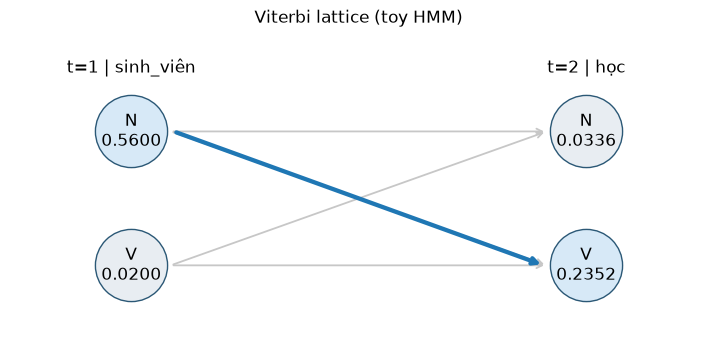

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
xpos = {0: 0, 1: 3}
ypos = {"N": 1, "V": 0}
for a in states:
    for b in states:
        ax.annotate("", xy=(2.74, ypos[b]), xytext=(0.26, ypos[a]),
                    arrowprops=dict(arrowstyle="->", color="0.78", lw=1.3))
ax.annotate("", xy=(2.72, ypos["V"]), xytext=(0.28, ypos["N"]),
            arrowprops=dict(arrowstyle="->", color="tab:blue", lw=3.1))
for t in range(2):
    for s in states:
        val = dp[t][s]
        ax.scatter(xpos[t], ypos[s], s=2700, zorder=3,
                   color=("#D7E9F7" if (t == 0 and s == "N") or (t == 1 and s == "V") else "#E8EDF2"),
                   edgecolors="#2B5876")
        ax.text(xpos[t], ypos[s], f"{s}\n{val:.4f}", ha="center", va="center", zorder=4, fontsize=12)
for t, token in enumerate(words):
    ax.text(xpos[t], 1.44, f"t={t+1} | {token}", ha="center", fontsize=12)
ax.set(xlim=(-0.8, 3.8), ylim=(-.55, 1.75))
ax.axis("off")
ax.set_title("Viterbi lattice (toy HMM)")
plt.show()

---
# PHẦN C · Huấn luyện HMM supervised và POS tiếng Việt

## C1. Từ corpus đến ước lượng tham số

Với dữ liệu đã gán nhãn, ta đếm:

- $C(i,j)$: số lần nhãn $j$ đi sau $i$.
- $C(j,x)$: số lần token $x$ xuất hiện với nhãn $j$.

Ước lượng MLE:

$$
\hat a_{ij}=\frac{C(i,j)}{\sum_k C(i,k)},\qquad
\hat b_j(x)=\frac{C(j,x)}{\sum_{x'} C(j,x')}.
$$

Khi một cặp chưa từng xuất hiện, MLE cho xác suất bằng $0$. Để tránh đường đi bị triệt tiêu, dùng **add-**$\alpha$ **smoothing**:

$$
\hat a_{ij}=\frac{C(i,j)+\alpha}{\sum_k C(i,k)+\alpha\lvert\mathcal{Y}_{next}\rvert},
$$

$$
\hat b_j(x)=\frac{C(j,x)+\alpha}{\sum_{x'}C(j,x')+\alpha(\lvert V\rvert+1)}.
$$

Trong code dưới đây, $V$ là vocabulary sau xử lý từ hiếm; $+1$ dành cho token `<UNK>`. Ta cũng thêm nhãn `<START>` và `<END>` để mô hình hóa đầu/cuối câu.

**Quan trọng:** đây là **supervised HMM** (biết nhãn trong train). Không phải Baum–Welch học HMM từ dữ liệu không nhãn.

## C2. Cài đặt HMM bậc 1 trong không gian log

Nếu câu dài, tích nhiều xác suất nhỏ có thể **underflow**. Ta dùng log:

$$
\log (abc)=\log a+\log b+\log c.
$$

Viterbi ở không gian log:

$$
D_t(j)=\log b_j(x_t)+\max_i\left[D_{t-1}(i)+\log a_{ij}\right].
$$

Cài đặt bên dưới dùng `Counter` để học tham số, `log` để tính, và tùy chọn `enforce_bio=True` để cấm đường đi BIO bất hợp lệ.

In [9]:
START, END, UNK = "<START>", "<END>", "<UNK>"

def valid_bio_step(previous, current):
    """Chỉ cấm I-X khi previous không phải B-X/I-X (cùng loại X)."""
    if not current.startswith("I-"):
        return True
    entity_type = current[2:]
    return previous in {f"B-{entity_type}", f"I-{entity_type}"}

@dataclass
class SupervisedHMM:
    alpha: float = 0.3
    unk_cutoff: int = 0
    tags: list = field(default_factory=list)
    vocab: set = field(default_factory=set)
    transition_counts: Counter = field(default_factory=Counter)
    transition_totals: Counter = field(default_factory=Counter)
    emission_counts: Counter = field(default_factory=Counter)
    emission_totals: Counter = field(default_factory=Counter)

    def fit(self, corpus):
        """corpus = [(tokens, tags), ...]; đã tách token và gán nhãn."""
        if self.alpha <= 0:
            raise ValueError("alpha phải > 0 để các log probability hữu hạn")
        token_frequency = Counter(w for words, _ in corpus for w in words)
        self.vocab = {w for w, n in token_frequency.items() if n > self.unk_cutoff}
        self.tags = sorted({y for _, labels in corpus for y in labels})
        self.transition_counts = Counter()
        self.transition_totals = Counter()
        self.emission_counts = Counter()
        self.emission_totals = Counter()
        if not self.tags:
            raise ValueError("Cần có ít nhất một câu gán nhãn")
        for tokens, labels in corpus:
            if len(tokens) != len(labels) or not tokens:
                raise ValueError("Mỗi câu phải có > 0 token và số token bằng số nhãn")
            previous = START
            for w, y in zip(tokens, labels):
                mapped = w if w in self.vocab else UNK
                self.transition_counts[(previous, y)] += 1
                self.transition_totals[previous] += 1
                self.emission_counts[(y, mapped)] += 1
                self.emission_totals[y] += 1
                previous = y
            self.transition_counts[(previous, END)] += 1
            self.transition_totals[previous] += 1
        return self

    def log_transition(self, previous, current):
        n_next = len(self.tags) + 1  # các nhãn thường + END
        p = (self.transition_counts[(previous, current)] + self.alpha) / (
            self.transition_totals[previous] + self.alpha * n_next
        )
        return math.log(p)

    def log_emission(self, tag, word):
        mapped = word if word in self.vocab else UNK
        p = (self.emission_counts[(tag, mapped)] + self.alpha) / (
            self.emission_totals[tag] + self.alpha * (len(self.vocab) + 1)
        )
        return math.log(p)

    def predict(self, tokens, enforce_bio=False, return_details=False):
        if not tokens:
            return ([], 0.0, [], []) if return_details else []
        scores, parents = [], []
        initial, bp_initial = {}, {}
        for s in self.tags:
            if enforce_bio and not valid_bio_step(START, s):
                continue
            initial[s] = self.log_transition(START, s) + self.log_emission(s, tokens[0])
            bp_initial[s] = START
        if not initial:
            raise ValueError("Không có trạng thái bắt đầu BIO hợp lệ")
        scores.append(initial)
        parents.append(bp_initial)
        for t in range(1, len(tokens)):
            current_scores, current_bp = {}, {}
            for state in self.tags:
                choices = [
                    (old_score + self.log_transition(prev, state), prev)
                    for prev, old_score in scores[-1].items()
                    if not enforce_bio or valid_bio_step(prev, state)
                ]
                if not choices:
                    continue
                best_score, best_prev = max(choices)
                current_scores[state] = best_score + self.log_emission(state, tokens[t])
                current_bp[state] = best_prev
            if not current_scores:
                raise ValueError("Không tồn tại đường đi BIO hợp lệ")
            scores.append(current_scores)
            parents.append(current_bp)
        last = max(scores[-1], key=lambda y: scores[-1][y] + self.log_transition(y, END))
        best_log_score = scores[-1][last] + self.log_transition(last, END)
        path = [last]
        for t in range(len(tokens)-1, 0, -1):
            path.append(parents[t][path[-1]])
        path.reverse()
        return (path, best_log_score, scores, parents) if return_details else path

### C3. Kiểm tra các tính chất của decoder

Đây là **unit tests cơ bản**; chúng cũng giúp xác nhận ràng buộc BIO và việc không gặp lỗi với token OOV.

In [10]:
assert valid_bio_step("B-PER", "I-PER")
assert valid_bio_step("I-PER", "I-PER")
assert not valid_bio_step(START, "I-PER")
assert not valid_bio_step("B-ORG", "I-PER")
assert valid_bio_step("O", "B-PER")
small = SupervisedHMM(alpha=0.1).fit([(["mèo", "ăn", "cá"], ["N", "V", "N"])])
assert len(small.predict(["mèo", "ăn", "cá"])) == 3
assert len(small.predict(["từ_mới", "ăn"])) == 2
print("✓ HMM, OOV và kiểm tra BIO: PASS")

✓ HMM, OOV và kiểm tra BIO: PASS


## C4. Dữ liệu POS tiếng Việt minh họa

Mỗi câu gồm cặp `(tokens, tags)`. Dữ liệu **được biên soạn cho mục tiêu dạy học**, dùng nhãn UPOS đơn giản và **không phải** một treebank được chú giải chính thức. Một số trường hợp trong ngôn ngữ tự nhiên cần quy tắc chú giải chi tiết hơn.

Chú ý:
- `Đại_học` và `Phenikaa` là **hai token** trong câu ví dụ; `Đại_học` được gán `NOUN`, `Phenikaa` là `PROPN` (minh họa).
- `Hà_Nội` là một token nhờ bước **word segmentation**.
- Khi dùng dữ liệu thực, phải dựa đúng vào hướng dẫn gán nhãn của corpus.

In [11]:
POS_CORPUS = [
    (["Tôi", "học", "NLP", "."], ["PRON", "VERB", "PROPN", "PUNCT"]),
    (["Bạn", "học", "Python", "."], ["PRON", "VERB", "PROPN", "PUNCT"]),
    (["Sinh_viên", "đọc", "sách", "."], ["NOUN", "VERB", "NOUN", "PUNCT"]),
    (["Giảng_viên", "dạy", "NLP", "."], ["NOUN", "VERB", "PROPN", "PUNCT"]),
    (["Sinh_viên", "học", "tại", "Phenikaa", "."], ["NOUN", "VERB", "ADP", "PROPN", "PUNCT"]),
    (["Tôi", "học", "tại", "Hà_Nội", "."], ["PRON", "VERB", "ADP", "PROPN", "PUNCT"]),
    (["Bạn", "làm_việc", "ở", "Hà_Nội", "."], ["PRON", "VERB", "ADP", "PROPN", "PUNCT"]),
    (["Nhà_trường", "tổ_chức", "hội_thảo", "."], ["NOUN", "VERB", "NOUN", "PUNCT"]),
    (["Chúng_tôi", "phân_tích", "dữ_liệu", "."], ["PRON", "VERB", "NOUN", "PUNCT"]),
    (["Họ", "xây_dựng", "mô_hình", "."], ["PRON", "VERB", "NOUN", "PUNCT"]),
    (["Mô_hình", "dự_đoán", "nhãn", "."], ["NOUN", "VERB", "NOUN", "PUNCT"]),
    (["Thuật_toán", "giải_mã", "chuỗi", "."], ["NOUN", "VERB", "NOUN", "PUNCT"]),
    (["Tài_liệu", "này", "rất", "hữu_ích", "."], ["NOUN", "DET", "ADV", "ADJ", "PUNCT"]),
    (["Bài_học", "này", "khá", "khó", "."], ["NOUN", "DET", "ADV", "ADJ", "PUNCT"]),
    (["Bài_tập", "mới", "rất", "thú_vị", "."], ["NOUN", "ADJ", "ADV", "ADJ", "PUNCT"]),
    (["Phòng_học", "mới", "rộng", "."], ["NOUN", "ADJ", "ADJ", "PUNCT"]),
    (["Chiếc", "bàn", "này", "đẹp", "."], ["NOUN", "NOUN", "DET", "ADJ", "PUNCT"]),
    (["Họ", "bàn", "kế_hoạch", "."], ["PRON", "VERB", "NOUN", "PUNCT"]),
    (["Cầu_thủ", "đá", "bóng", "."], ["NOUN", "VERB", "NOUN", "PUNCT"]),
    (["Viên", "đá", "rất", "nặng", "."], ["NOUN", "NOUN", "ADV", "ADJ", "PUNCT"]),
    (["Bạn", "có_thể", "học", "tốt", "."], ["PRON", "AUX", "VERB", "ADJ", "PUNCT"]),
    (["Tôi", "sẽ", "đọc", "báo", "."], ["PRON", "AUX", "VERB", "NOUN", "PUNCT"]),
    (["Giảng_viên", "và", "sinh_viên", "thảo_luận", "."], ["NOUN", "CCONJ", "NOUN", "VERB", "PUNCT"]),
    (["Hệ_thống", "nhận_dạng", "thực_thể", "."], ["NOUN", "VERB", "NOUN", "PUNCT"]),
    (["Nhóm", "nghiên_cứu", "công_nghệ", "."], ["NOUN", "VERB", "NOUN", "PUNCT"]),
    (["Nghiên_cứu", "này", "rất", "quan_trọng", "."], ["NOUN", "DET", "ADV", "ADJ", "PUNCT"]),
    (["Hà_Nội", "là", "thủ_đô", "."], ["PROPN", "AUX", "NOUN", "PUNCT"]),
    (["Đà_Nẵng", "là", "thành_phố", "đẹp", "."], ["PROPN", "AUX", "NOUN", "ADJ", "PUNCT"]),
    (["Việt_Nam", "có", "nhiều", "trường_đại_học", "."], ["PROPN", "VERB", "ADJ", "NOUN", "PUNCT"]),
    (["Hai", "sinh_viên", "đạt", "giải", "."], ["NUM", "NOUN", "VERB", "NOUN", "PUNCT"]),
    (["Các", "nhà_khoa_học", "phân_tích", "dữ_liệu", "."], ["DET", "NOUN", "VERB", "NOUN", "PUNCT"]),
    (["Dữ_liệu", "lớn", "đòi_hỏi", "thuật_toán", "tốt", "."], ["NOUN", "ADJ", "VERB", "NOUN", "ADJ", "PUNCT"]),
]
assert all(len(x) == len(y) for x, y in POS_CORPUS)
print("Số câu:", len(POS_CORPUS))
print("Tập nhãn:", sorted({tag for _, ys in POS_CORPUS for tag in ys}))
print("5 câu minh họa:")
for words_, tags_ in POS_CORPUS[:5]:
    print("  ", " ".join(f"{w}/{y}" for w, y in zip(words_, tags_)))

Số câu: 32
Tập nhãn: ['ADJ', 'ADP', 'ADV', 'AUX', 'CCONJ', 'DET', 'NOUN', 'NUM', 'PRON', 'PROPN', 'PUNCT', 'VERB']
5 câu minh họa:
   Tôi/PRON học/VERB NLP/PROPN ./PUNCT
   Bạn/PRON học/VERB Python/PROPN ./PUNCT
   Sinh_viên/NOUN đọc/VERB sách/NOUN ./PUNCT
   Giảng_viên/NOUN dạy/VERB NLP/PROPN ./PUNCT
   Sinh_viên/NOUN học/VERB tại/ADP Phenikaa/PROPN ./PUNCT


## C5. Tách train/test ở **cấp câu**

Không chia ngẫu nhiên các token của **cùng một câu** sang cả train và test, vì gây rò rỉ thông tin ngữ cảnh. Tập dữ liệu nhỏ này chỉ nhằm kiểm tra thuật toán.

$$
\text{OOV rate}=\frac{\#\{x\in test : x\notin V_{train}\}}{\#\text{ tokens trong test}}.
$$

In [12]:
def split_sentences(corpus, test_ratio=0.25, seed=42):
    ids = list(range(len(corpus)))
    random.Random(seed).shuffle(ids)
    cut = max(1, round(len(ids) * test_ratio))
    test_set = set(ids[:cut])
    return ([corpus[i] for i in range(len(corpus)) if i not in test_set],
            [corpus[i] for i in range(len(corpus)) if i in test_set])

def corpus_summary(corpus):
    tokens = [w for xs, _ in corpus for w in xs]
    labels = [y for _, ys in corpus for y in ys]
    return {"sentences": len(corpus), "tokens": len(tokens),
            "vocab": len(set(tokens)), "tags": len(set(labels))}

def oov_rate(train, test):
    vocab = {w for xs, _ in train for w in xs}
    test_words = [w for xs, _ in test for w in xs]
    return sum(w not in vocab for w in test_words) / len(test_words)

pos_train, pos_test = split_sentences(POS_CORPUS, test_ratio=.25, seed=SEED)
display(pd.DataFrame({"train": corpus_summary(pos_train), "test": corpus_summary(pos_test)}))
print(f"POS OOV rate: {oov_rate(pos_train, pos_test):.1%}")

,train,test
sentences,24,8
tokens,110,36
vocab,68,27
tags,11,11


POS OOV rate: 50.0%


## C6. Huấn luyện, dự đoán và baseline

**Most-frequent-tag baseline**: dự đoán mỗi token bằng nhãn thường xuất hiện nhất của token đó trong train. Nếu token chưa gặp, dùng nhãn phổ biến nhất toàn bộ tập train.

Dù đơn giản, baseline này là mốc tham chiếu quan trọng; HMM không phải lúc nào cũng thắng trên corpus quá nhỏ.

In [13]:
def fit_mft_baseline(corpus):
    by_word = defaultdict(Counter)
    global_counts = Counter()
    for tokens, labels in corpus:
        for w, y in zip(tokens, labels):
            by_word[w][y] += 1
            global_counts[y] += 1
    fallback = global_counts.most_common(1)[0][0]
    return lambda words_: [by_word[w].most_common(1)[0][0] if w in by_word else fallback for w in words_]

def token_accuracy(corpus, predict_fn):
    correct = total = 0
    for tokens, gold in corpus:
        pred = predict_fn(tokens)
        assert len(pred) == len(gold)
        correct += sum(a == b for a, b in zip(pred, gold))
        total += len(gold)
    return correct / total if total else 0

mft = fit_mft_baseline(pos_train)
pos_hmm = SupervisedHMM(alpha=.3, unk_cutoff=0).fit(pos_train)
results_pos = pd.DataFrame([
    {"Mô hình": "Most frequent tag", "Token accuracy": token_accuracy(pos_test, mft)},
    {"Mô hình": "HMM + Viterbi", "Token accuracy": token_accuracy(pos_test, pos_hmm.predict)}
])
display(results_pos)
print("Ví dụ câu mới:")
new_pos_sentence = ["Sinh_viên", "học", "ở", "Hà_Nội", "."]
print(" ".join(f"{w}/{y}" for w, y in zip(new_pos_sentence, pos_hmm.predict(new_pos_sentence))))

,Mô hình,Token accuracy
0,Most frequent tag,0.694444
1,HMM + Viterbi,0.694444


Ví dụ câu mới:
Sinh_viên/NOUN học/VERB ở/NOUN Hà_Nội/ADJ ./PUNCT


## C7. Đọc lỗi POS: mô hình sai ở đâu?

Accuracy ở đây phụ thuộc mạnh vào cách chia tập và vocab hiếm. Một bảng dự đoán sai giúp tìm xem lỗi đến từ **OOV**, **nhập nhằng ngữ cảnh** hay **độ thưa dữ liệu**.

In [14]:
def collect_token_errors(corpus, predict_fn, max_rows=20):
    rows = []
    for sent_id, (words_, gold) in enumerate(corpus):
        pred = predict_fn(words_)
        for t, (w, y, y_hat) in enumerate(zip(words_, gold, pred)):
            if y != y_hat:
                rows.append({"sentence_id": sent_id, "context": " ".join(words_),
                             "token": w, "gold": y, "pred": y_hat, "position": t})
    return pd.DataFrame(rows, columns=["sentence_id", "context", "token", "gold", "pred", "position"]).head(max_rows)

display(collect_token_errors(pos_test, pos_hmm.predict))

,sentence_id,context,token,gold,pred,position
0,1,Bạn làm_việc ở Hà_Nội .,làm_việc,VERB,AUX,1
1,1,Bạn làm_việc ở Hà_Nội .,ở,ADP,VERB,2
2,1,Bạn làm_việc ở Hà_Nội .,Hà_Nội,PROPN,NOUN,3
3,2,Mô_hình dự_đoán nhãn .,Mô_hình,NOUN,PRON,0
4,3,Thuật_toán giải_mã chuỗi .,Thuật_toán,NOUN,PRON,0
5,4,Phòng_học mới rộng .,Phòng_học,NOUN,PRON,0
6,4,Phòng_học mới rộng .,mới,ADJ,VERB,1
7,4,Phòng_học mới rộng .,rộng,ADJ,NOUN,2
8,5,Giảng_viên và sinh_viên thảo_luận .,và,CCONJ,VERB,1
9,5,Giảng_viên và sinh_viên thảo_luận .,thảo_luận,VERB,ADJ,3


### C8. Quan sát tác động của smoothing và OOV

- $\alpha$ nhỏ: xác suất gần với đếm thô, nhưng nhạy với cặp hiếm.
- $\alpha$ lớn: phân phối đều hơn, có thể làm mất tín hiệu của mẫu quan sát được.
- `unk_cutoff=1`: mọi từ chỉ xuất hiện **một lần** trong train được nhóm thành `<UNK>` trong quá trình ước lượng phát xạ.

**Câu hỏi:** thay đổi $\alpha$ có luôn làm accuracy tăng không? Vì sao không?

In [15]:
grid = []
for alpha in [0.01, 0.1, 0.3, 1.0]:
    for cutoff in [0, 1]:
        candidate = SupervisedHMM(alpha=alpha, unk_cutoff=cutoff).fit(pos_train)
        grid.append({"alpha": alpha, "unk_cutoff": cutoff,
                     "vocab_size": len(candidate.vocab),
                     "test_accuracy": token_accuracy(pos_test, candidate.predict)})
display(pd.DataFrame(grid))
print("Ghi nhớ: đây chỉ là thử nghiệm trên toy data; không chọn hyperparameters trên test set trong đánh giá thực tế.")

,alpha,unk_cutoff,vocab_size,test_accuracy
0,0.01,0,68,0.694444
1,0.01,1,16,0.694444
2,0.10,0,68,0.694444
3,0.10,1,16,0.694444
4,0.30,0,68,0.694444
5,0.30,1,16,0.722222
6,1.00,0,68,0.638889
7,1.00,1,16,0.722222


Ghi nhớ: đây chỉ là thử nghiệm trên toy data; không chọn hyperparameters trên test set trong đánh giá thực tế.


---
# PHẦN D · NER, BIO và đánh giá theo span

## D1. NER = tìm **ranh giới** + **loại thực thể**

Ví dụ: `Nguyễn/Văn/An` là một span `PER`; `Đại_học/Phenikaa` là một span `ORG`.

Đối với NER, việc dự đoán đúng từng nhãn riêng lẻ chưa đảm bảo nhận diện đúng toàn bộ thực thể. Một thực thể cần khớp:

1. **Vị trí bắt đầu** (`start`),
2. **Vị trí kết thúc** (`end`, theo quy ước loại trừ),
3. **Loại thực thể** (`PER`, `ORG`, `LOC`, ...).

Chẳng hạn vàng `(0,3,PER)` và dự đoán `(0,2,PER)` được tính là **không khớp** ở đánh giá strict entity-level.

In [16]:
def bio_to_spans(tags):
    """(start, end_exclusive, type). Với I-X bất hợp lệ, sửa như B-X.
    Quy tắc sửa cần được công bố nhất quán khi đánh giá.
    """
    spans = []
    current_type = None
    start = None
    for i, tag in enumerate(list(tags) + ["O"]):
        if tag == "O":
            typ, prefix = None, "O"
        elif "-" in tag:
            prefix, typ = tag.split("-", 1)
            if prefix not in ("B", "I") or not typ:
                raise ValueError("Nhãn BIO không hợp lệ: " + tag)
        else:
            raise ValueError("Nhãn BIO không hợp lệ: " + tag)
        must_close = current_type is not None and (
            prefix == "O" or prefix == "B" or typ != current_type
        )
        if must_close:
            spans.append((start, i, current_type))
            current_type, start = None, None
        if prefix == "B" or (prefix == "I" and current_type is None):
            current_type, start = typ, i
    return spans

example_spans = bio_to_spans(ner_labels)
print("Spans:", example_spans)
for start, end, typ in example_spans:
    print(f"{typ:4s}: {' '.join(ner_tokens[start:end])} | [{start}, {end})")
assert example_spans == [(0, 3, "PER"), (5, 7, "ORG")]
assert bio_to_spans(["O", "B-LOC", "I-LOC", "O"]) == [(1, 3, "LOC")]

Spans: [(0, 3, 'PER'), (5, 7, 'ORG')]
PER : Nguyễn Văn An | [0, 3)
ORG : Đại_học Phenikaa | [5, 7)


## D2. Đánh giá NER theo thực thể (strict span match)

Gọi $TP$ là số span dự đoán khớp chính xác với gold (đúng **bắt đầu, kết thúc, loại**); $FP$ là span dự đoán thừa/sai và $FN$ là span vàng bị bỏ sót:

$$
\mathrm{Precision}=\frac{TP}{TP+FP},\qquad
\mathrm{Recall}=\frac{TP}{TP+FN},
$$

$$
F_1=\frac{2\,\mathrm{Precision}\,\mathrm{Recall}}{\mathrm{Precision}+\mathrm{Recall}}.
$$

Đây là **micro entity-level F1**: cộng $TP, FP, FN$ từ **tất cả câu** trước khi tính.

Hàm dưới đây tránh lỗi so sánh các span có cùng tọa độ nhưng thuộc **hai câu khác nhau**.

In [17]:
def entity_scores(gold_sequences, pred_sequences):
    if len(gold_sequences) != len(pred_sequences):
        raise ValueError("Khác số câu")
    tp = fp = fn = 0
    for g, p in zip(gold_sequences, pred_sequences):
        if len(g) != len(p):
            raise ValueError("Gold và pred không cùng chiều dài")
        gold = set(bio_to_spans(g))
        pred = set(bio_to_spans(p))
        tp += len(gold & pred)
        fp += len(pred - gold)
        fn += len(gold - pred)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"TP": tp, "FP": fp, "FN": fn,
            "precision": precision, "recall": recall, "f1": f1}

gold_demo = [["B-PER", "I-PER", "I-PER", "O", "B-LOC"]]
pred_demo = [["B-PER", "I-PER", "O", "O", "B-LOC"]]
print("Nếu dự đoán thiếu một token trong PER:", entity_scores(gold_demo, pred_demo))
assert entity_scores(gold_demo, pred_demo)["TP"] == 1
assert entity_scores(gold_demo, pred_demo)["FP"] == 1
assert entity_scores(gold_demo, pred_demo)["FN"] == 1

Nếu dự đoán thiếu một token trong PER: {'TP': 1, 'FP': 1, 'FN': 1, 'precision': 0.5, 'recall': 0.5, 'f1': 0.5}


## D3. Corpus NER minh họa

Đây cũng là **toy corpus**, không phải NER.csv của Lab 7. Mô hình thử nghiệm chỉ dùng `PER`, `ORG`, `LOC`, `O`, ở những ngữ cảnh đơn giản. Trong dự án thực tế cần nhiều dữ liệu, guideline BIO nhất quán và kiểm tra lỗi chú giải.

In [18]:
NER_CORPUS = [
    (["Nguyễn", "Văn", "An", "làm_việc", "tại", "Đại_học", "Phenikaa", "."], ["B-PER", "I-PER", "I-PER", "O", "O", "B-ORG", "I-ORG", "O"]),
    (["Trần", "Thu", "Hà", "học", "ở", "Hà_Nội", "."], ["B-PER", "I-PER", "I-PER", "O", "O", "B-LOC", "O"]),
    (["Lê", "Minh", "làm_việc", "tại", "FPT", "."], ["B-PER", "I-PER", "O", "O", "B-ORG", "O"]),
    (["Phạm", "Lan", "ở", "Đà_Nẵng", "."], ["B-PER", "I-PER", "O", "B-LOC", "O"]),
    (["Vũ", "Anh", "thăm", "Việt_Nam", "."], ["B-PER", "I-PER", "O", "B-LOC", "O"]),
    (["Đại_học", "Phenikaa", "ở", "Hà_Nội", "."], ["B-ORG", "I-ORG", "O", "B-LOC", "O"]),
    (["Công_ty", "FPT", "tuyển_dụng", "kỹ_sư", "."], ["B-ORG", "I-ORG", "O", "O", "O"]),
    (["VinAI", "tổ_chức", "hội_thảo", "tại", "Hà_Nội", "."], ["B-ORG", "O", "O", "O", "B-LOC", "O"]),
    (["Nguyễn", "Văn", "An", "đến", "Đà_Nẵng", "."], ["B-PER", "I-PER", "I-PER", "O", "B-LOC", "O"]),
    (["Trần", "Thu", "Hà", "đọc", "báo", "."], ["B-PER", "I-PER", "I-PER", "O", "O", "O"]),
    (["FPT", "đặt", "văn_phòng", "tại", "Việt_Nam", "."], ["B-ORG", "O", "O", "O", "B-LOC", "O"]),
    (["Đại_học", "Phenikaa", "mời", "Lê", "Minh", "."], ["B-ORG", "I-ORG", "O", "B-PER", "I-PER", "O"]),
    (["Phạm", "Lan", "đến", "Công_ty", "FPT", "."], ["B-PER", "I-PER", "O", "B-ORG", "I-ORG", "O"]),
    (["Vũ", "Anh", "học", "ở", "Đại_học", "Phenikaa", "."], ["B-PER", "I-PER", "O", "O", "B-ORG", "I-ORG", "O"]),
    (["Hà_Nội", "đón", "đoàn", "khách", "."], ["B-LOC", "O", "O", "O", "O"]),
    (["Đà_Nẵng", "tổ_chức", "sự_kiện", "."], ["B-LOC", "O", "O", "O"]),
    (["Việt_Nam", "có", "nhiều", "trường", "."], ["B-LOC", "O", "O", "O", "O"]),
    (["Lê", "Minh", "gặp", "Nguyễn", "Văn", "An", "."], ["B-PER", "I-PER", "O", "B-PER", "I-PER", "I-PER", "O"]),
    (["VinAI", "và", "FPT", "hợp_tác", "."], ["B-ORG", "O", "B-ORG", "O", "O"]),
    (["Trần", "Thu", "Hà", "đến", "Đại_học", "Phenikaa", "."], ["B-PER", "I-PER", "I-PER", "O", "B-ORG", "I-ORG", "O"]),
    (["Nguyễn", "Văn", "An", "gặp", "Phạm", "Lan", "tại", "Hà_Nội", "."], ["B-PER", "I-PER", "I-PER", "O", "B-PER", "I-PER", "O", "B-LOC", "O"]),
    (["FPT", "có", "trụ_sở", "ở", "Việt_Nam", "."], ["B-ORG", "O", "O", "O", "B-LOC", "O"]),
    (["Đại_học", "Phenikaa", "hợp_tác", "với", "VinAI", "."], ["B-ORG", "I-ORG", "O", "O", "B-ORG", "O"]),
    (["Phạm", "Lan", "tham_dự", "hội_thảo", "tại", "Đà_Nẵng", "."], ["B-PER", "I-PER", "O", "O", "O", "B-LOC", "O"]),
]
assert all(len(words_) == len(tags_) for words_, tags_ in NER_CORPUS)
assert all(all(valid_bio_step((tags_[t-1] if t else START), tags_[t]) for t in range(len(tags_))) for _, tags_ in NER_CORPUS)
print("Số câu NER:", len(NER_CORPUS))
print("BIO labels:", sorted({tag for _, ys in NER_CORPUS for tag in ys}))

Số câu NER: 24
BIO labels: ['B-LOC', 'B-ORG', 'B-PER', 'I-ORG', 'I-PER', 'O']


## D4. Huấn luyện HMM cho NER

HMM dự đoán chuỗi BIO như POS, nhưng:

1. **Không cho phép** chuyển `O → I-PER` hay `B-ORG → I-PER`.
2. Đánh giá **span-level F1** bên cạnh token accuracy.
3. Bài toán NER trên corpus nhỏ thường rất khó với HMM vì tên riêng và ngữ cảnh có tỷ lệ OOV cao.

**Đọc kết quả:** điểm số toy chỉ dùng để debug; không dùng để suy luận hiệu năng của thuật toán trong sản phẩm thật.

In [19]:
ner_train, ner_test = split_sentences(NER_CORPUS, test_ratio=.25, seed=SEED)
ner_hmm = SupervisedHMM(alpha=.3, unk_cutoff=0).fit(ner_train)
ner_gold = [tags for _, tags in ner_test]
ner_pred = [ner_hmm.predict(words_, enforce_bio=True) for words_, _ in ner_test]
print("NER train / test:", len(ner_train), "/", len(ner_test))
print("NER OOV rate:", f"{oov_rate(ner_train, ner_test):.1%}")
print("NER token accuracy:", f"{token_accuracy(ner_test, lambda w: ner_hmm.predict(w, enforce_bio=True)):.2%}")
print("NER strict entity-level metrics:")
display(pd.DataFrame([entity_scores(ner_gold, ner_pred)]))

NER train / test: 18 / 6
NER OOV rate: 14.7%
NER token accuracy: 85.29%
NER strict entity-level metrics:


,TP,FP,FN,precision,recall,f1
0,7,4,4,0.636364,0.636364,0.636364


## D5. Trực tiếp xem các thực thể đã trích xuất

Một span được biểu diễn bằng `(start, end, type)`; `end` là vị trí **không bao gồm**. Dùng đoạn mã này để quan sát các lỗi cắt nhầm biên thực thể.

In [20]:
def describe_spans(words_, tags_):
    return [(" ".join(words_[start:end]), typ) for start, end, typ in bio_to_spans(tags_)]

for i, (words_, gold) in enumerate(ner_test[:5]):
    pred = ner_hmm.predict(words_, enforce_bio=True)
    print(f"Câu {i+1}: {' '.join(words_)}")
    print("  Gold:", describe_spans(words_, gold))
    print("  Pred:", describe_spans(words_, pred))
    print("  BIO :", " ".join(pred))
    print()

Câu 1: Đại_học Phenikaa ở Hà_Nội .
  Gold: [('Đại_học Phenikaa', 'ORG'), ('Hà_Nội', 'LOC')]
  Pred: [('Đại_học Phenikaa', 'ORG'), ('Hà_Nội', 'LOC')]
  BIO : B-ORG I-ORG O B-LOC O

Câu 2: FPT đặt văn_phòng tại Việt_Nam .
  Gold: [('FPT', 'ORG'), ('Việt_Nam', 'LOC')]
  Pred: [('FPT đặt', 'ORG'), ('Việt_Nam', 'LOC')]
  BIO : B-ORG I-ORG O O B-LOC O

Câu 3: Vũ Anh học ở Đại_học Phenikaa .
  Gold: [('Vũ Anh', 'PER'), ('Đại_học Phenikaa', 'ORG')]
  Pred: [('Vũ Anh', 'PER'), ('Đại_học Phenikaa', 'ORG')]
  BIO : B-PER I-PER O O B-ORG I-ORG O

Câu 4: Đà_Nẵng tổ_chức sự_kiện .
  Gold: [('Đà_Nẵng', 'LOC')]
  Pred: [('Đà_Nẵng', 'LOC'), ('sự_kiện', 'LOC')]
  BIO : B-LOC O B-LOC O

Câu 5: VinAI và FPT hợp_tác .
  Gold: [('VinAI', 'ORG'), ('FPT', 'ORG')]
  Pred: [('VinAI và FPT', 'ORG')]
  BIO : B-ORG I-ORG I-ORG O O



## D6. Ràng buộc BIO có tạo khác biệt?

Thử so sánh **cùng một HMM** với/không với `enforce_bio`. Trong mô hình smoothing, những chuyển trạng thái chưa gặp vẫn có xác suất dương nên có thể phát sinh `I-X` sai quy ước nếu không áp ràng buộc.

**Lưu ý:** kết quả hai phiên bản trên toy data *có thể bằng nhau*; sự trùng nhau không chứng minh ràng buộc BIO là không cần thiết.

In [21]:
ner_rows = []
for constrained in [False, True]:
    preds = [ner_hmm.predict(xs, enforce_bio=constrained) for xs, _ in ner_test]
    sc = entity_scores(ner_gold, preds)
    bad = sum(not valid_bio_step((p[t-1] if t else START), p[t])
              for p in preds for t in range(len(p)))
    ner_rows.append({"BIO constrained": constrained, "Invalid BIO edges": bad,
                     "Entity P": sc["precision"], "Entity R": sc["recall"], "Entity F1": sc["f1"]})
display(pd.DataFrame(ner_rows))

,BIO constrained,Invalid BIO edges,Entity P,Entity R,Entity F1
0,False,0,0.636364,0.636364,0.636364
1,True,0,0.636364,0.636364,0.636364


---
# PHẦN E · Làm việc với dữ liệu thật của Lab 7 (tùy chọn)

Theo tài liệu `Lab 7 POS Tagging.pdf` của học phần, yêu cầu thực hành gồm:

- NER tiếng Anh trên tập `NER.csv`: khảo sát nhãn và vocabulary; train/test; HMM; Viterbi; đánh giá.
- POS tiếng Việt trên `vi_train.txt`, `vi_test.txt` theo tài liệu mô tả nhãn đi kèm.

**Các file dữ liệu cụ thể không có trong gói PDF tài liệu hiện tại.** Vì vậy notebook không tự giả định schema của các file đó. Bên dưới có công cụ đọc định dạng phổ biến và thông báo khi cần sửa parser. Chỉ chạy các ô này **sau khi đã upload dữ liệu**.

Trên Colab có thể sử dụng:

```python
# from google.colab import files
# uploaded = files.upload()
```

**Đề xuất:** đọc 5–10 dòng đầu của dữ liệu, xác nhận delimiter, cột `sentence`, `token`, `tag`, ranh giới câu; chỉ sau đó mới huấn luyện và đánh giá.

In [22]:
print("File cần chuẩn bị:", [str(p) for p in [Path("NER.csv"), Path("vi_train.txt"), Path("vi_test.txt")]])
for name in ["NER.csv", "vi_train.txt", "vi_test.txt"]:
    p = Path(name)
    if p.exists():
        print(f"✓ {name} có sẵn, kích thước {p.stat().st_size:,} bytes")
    else:
        print(f"– {name} chưa có; dùng toy corpus ở các phần trước")

File cần chuẩn bị: ['NER.csv', 'vi_train.txt', 'vi_test.txt']
– NER.csv chưa có; dùng toy corpus ở các phần trước
✓ vi_train.txt có sẵn, kích thước 1,664,452 bytes
✓ vi_test.txt có sẵn, kích thước 200,159 bytes


### E1. Ví dụ parser: NER.csv theo dạng `Sentence #, Word, Tag`

Một số bộ dữ liệu NER công khai có những cột này; **chúng ta không biết trước** `NER.csv` đang dùng trong Lab 7 có đúng cấu trúc đó hay không. Hàm có kiểm tra đầu vào và sẽ báo lỗi nếu không phù hợp.

Sau khi tải file, nên xem `data.head()` và `data.columns` để kiểm tra thực tế.

In [23]:
def read_ner_csv_if_compatible(path="NER.csv"):
    df = pd.read_csv(path)
    required = {"Sentence #", "Word", "Tag"}
    if not required.issubset(df.columns):
        raise ValueError(f"CSV có các cột {list(df.columns)}; parser ví dụ cần {sorted(required)}. "
                         "Hãy viết parser phù hợp với file thực tế.")
    df["Sentence #"] = df["Sentence #"].ffill()
    if df[["Sentence #", "Word", "Tag"]].isna().any().any():
        raise ValueError("Có ô thiếu sentence id/token/tag; cần làm sạch dữ liệu")
    grouped = []
    for _, group in df.groupby("Sentence #", sort=False):
        toks = group["Word"].astype(str).tolist()
        labels = group["Tag"].astype(str).tolist()
        grouped.append((toks, labels))
    return grouped

if Path("NER.csv").exists():
    print("Cột dữ liệu:", pd.read_csv("NER.csv", nrows=3).columns.tolist())
    try:
        ner_real = read_ner_csv_if_compatible("NER.csv")
        print("Đọc thành công:", corpus_summary(ner_real))
    except (ValueError, KeyError) as exc:
        print("Cần điều chỉnh parser:", exc)
else:
    print("Chưa có NER.csv — bỏ qua; demo NER sử dụng dữ liệu minh họa.")

Chưa có NER.csv — bỏ qua; demo NER sử dụng dữ liệu minh họa.


### E2. Ví dụ parser: CoNLL/TSV cho tiếng Việt

Hàm sau hỗ trợ dạng mỗi dòng `token<TAB>tag` (hoặc phân tách bằng khoảng trắng) và **dòng trắng kết thúc câu**, ví dụ:

```text
Sinh_viên    N
học          V
NLP          Np

Hà_Nội       Np
đẹp          A
```

Đây **chỉ là một định dạng ví dụ**. Không tự động sửa nhãn thành UPOS. Nếu `vi_train.txt`/`vi_test.txt` sử dụng một định dạng khác, hãy điều chỉnh đúng theo file hướng dẫn nhãn của Lab 7 trước khi áp dụng.

In [24]:
def read_conll_2columns(path):
    sentences, tokens, tags = [], [], []
    with open(path, encoding="utf-8-sig") as f:
        for lineno, raw in enumerate(f, 1):
            line = raw.strip()
            if not line:
                if tokens:
                    sentences.append((tokens, tags))
                    tokens, tags = [], []
                continue
            if line.startswith("#"):
                continue
            parts = line.split()
            if len(parts) != 2:
                raise ValueError(f"Dòng {lineno}: cần đúng 2 cột token/tag, nhận {parts[:6]}")
            token, tag = parts
            tokens.append(token)
            tags.append(tag)
    if tokens:
        sentences.append((tokens, tags))
    return sentences

if Path("vi_train.txt").exists() and Path("vi_test.txt").exists():
    try:
        vi_train = read_conll_2columns("vi_train.txt")
        vi_test = read_conll_2columns("vi_test.txt")
        print("Vietnamese POS (actual files):", corpus_summary(vi_train), corpus_summary(vi_test))
    except ValueError as exc:
        print("Parser minh họa chưa phù hợp, cần xem lại định dạng:", exc)
else:
    print("Chưa có 2 file vi_train.txt / vi_test.txt — bỏ qua, không giả định cấu trúc.")

Parser minh họa chưa phù hợp, cần xem lại định dạng: Dòng 2: cần đúng 2 cột token/tag, nhận ['Trên/E', 'đường/N', 'đi/V', ',/,', 'có/V', 'một/M']


### E3. Checklist khi chuyển từ demo sang dữ liệu thật

1. Mỗi câu phải có số token **bằng** số nhãn.
2. Split train/test theo **câu hoặc văn bản**; tuyệt đối không có câu trùng giữa train và test.
3. Mô hình HMM cần được fit **chỉ với train** (vocabulary, tần suất, smoothing, xử lý OOV).
4. Với dữ liệu POS Việt, xem tài liệu nhãn: `N`, `Np`, `V`, `A`, ... không đương nhiên tương ứng 1–1 với UPOS.
5. Với NER, kiểm tra schema `BIO`, `BIOES` hay nhãn khác; cần chuyển đổi trước khi `bio_to_spans`.
6. Đánh giá POS theo **token accuracy**; NER ít nhất theo **strict entity-level P/R/F1**.
7. Thử nhiều giá trị $\alpha$ trên **validation set**; chỉ báo cáo test sau khi chốt mô hình.
8. Viết phần phân tích ít nhất **5 lỗi điển hình**, không chỉ cung cấp một chỉ số tổng hợp.

---
# PHẦN F · Bài tập thực hành (sinh viên tự hoàn thiện)

**Quy ước:** sinh viên thay `return None` hoặc phần `# TODO` bằng code. Các kiểm thử chỉ chạy khi bài đã có kết quả để notebook vẫn có thể *Run all* trước giờ học.

Các bài 1–4 là bắt buộc; 5–6 nâng cao.

## Bài 1 (10 điểm) — Đếm cặp nhãn chuyển trạng thái

Viết `count_tag_bigrams(corpus)` trả về `Counter` chứa các cặp `(nhãn trước, nhãn hiện tại)`, **kể cả** `<START>` và `<END>`. Với một câu có nhãn `[N,V,N]`, phải thu được đúng 4 chuyển trạng thái.

**Gợi ý:** dùng `Counter`, `zip([START]+tags, tags+[END])`.

In [25]:
def count_tag_bigrams(corpus):
    # TODO (SV): viết phần thân hàm, trả về Counter({(old_tag, new_tag): count})
    counts = Counter()
    for _, tags in corpus:
        # Tạo chuỗi nhãn bao gồm <START> và <END>
        extended = [START] + list(tags) + [END]
        for prev_tag, curr_tag in zip(extended[:-1], extended[1:]):
            counts[(prev_tag, curr_tag)] += 1
    return counts

check_1 = count_tag_bigrams([(["mèo", "ăn", "cá"], ["N", "V", "N"])])
if check_1 is None:
    print("Bài 1: TODO — chưa có lời giải")
else:
    expected = Counter({(START, "N"):1, ("N","V"):1, ("V","N"):1, ("N",END):1})
    assert check_1 == expected, (check_1, expected)
    print("✓ Bài 1: PASS")

Bài 1: TODO — chưa có lời giải


## Bài 2 (10 điểm) — Ước lượng xác suất chuyển

Viết hàm $\hat a_{ij}$ theo công thức smoothing:

$$
\hat a_{ij}=\frac{C(i,j)+\alpha}{C(i)+\alpha K},
$$

với $K$ là số lựa chọn trạng thái **đầu ra** từ $i$ theo giả định của bài; $C(i)$ là tổng số lần chuyển ra khỏi $i$.

Kiểm thử: $C(N,V)=3$, $C(N)=5$, $\alpha=1$, $K=2$ thì $P(V\mid N)=4/7$.

In [26]:
def smoothed_transition_probability(pair_count, outgoing_count, alpha, num_choices):
    # TODO (SV): trả về xác suất add-alpha
    # Công thức: P(j | i) = (C(i, j) + alpha) / (C(i) + alpha * K)
    return (pair_count + alpha) / (outgoing_count + alpha * num_choices)

check_2 = smoothed_transition_probability(3, 5, 1, 2)
if check_2 is None:
    print("Bài 2: TODO — chưa có lời giải")
else:
    assert math.isclose(check_2, 4/7, rel_tol=1e-12)
    print("✓ Bài 2: PASS")

Bài 2: TODO — chưa có lời giải


## Bài 3 (15 điểm) — Tự viết Viterbi, không gọi `toy_viterbi`

Hoàn thiện `student_viterbi` cho HMM bậc 1 **không có `<END>`**. Kết quả là `list` nhãn tối ưu.

Yêu cầu dùng **DP + backpointer**, không được dùng `itertools.product` để vét cạn. Kiểm thử với xác suất của các slide Module 6: $[N,V]$.

In [27]:
def student_viterbi(tokens, states, pi, A, B):
    # TODO (SV): khởi tạo delta; duyệt t=1..T-1; truy vết backpointer
    if not tokens:
        return []
        
    # Bước 1: Khởi tạo tại t = 0
    dp = {}
    for s in states:
        emit = B[s].get(tokens[0], B[s].get("_OTHER_", 0.0))
        dp[s] = pi[s] * emit
        
    backpointers = []
    
    # Bước 2: Quy hoạch động duyệt t = 1 .. T-1
    for t in range(1, len(tokens)):
        new_dp = {}
        bp_t = {}
        token = tokens[t]
        for curr in states:
            emit = B[curr].get(token, B[curr].get("_OTHER_", 0.0))
            best_prev = max(states, key=lambda prev: dp[prev] * A[prev][curr])
            new_dp[curr] = dp[best_prev] * A[best_prev][curr] * emit
            bp_t[curr] = best_prev
        dp = new_dp
        backpointers.append(bp_t)
        
    # Bước 3: Tìm trạng thái cuối cùng có xác suất DP lớn nhất (không có <END>)
    last_state = max(states, key=lambda s: dp[s])
    
    # Bước 4: Truy vết ngược backpointer
    path = [last_state]
    for bp_t in reversed(backpointers):
        path.append(bp_t[path[-1]])
    path.reverse()
    
    return path

check_3 = student_viterbi(words, states, pi, A, B)
if check_3 is None:
    print("Bài 3: TODO — chưa có lời giải")
else:
    assert check_3 == ["N", "V"]
    print("✓ Bài 3: PASS")

Bài 3: TODO — chưa có lời giải


## Bài 4 (15 điểm) — BIO sang span (NER)

Viết `student_bio_to_spans(tags)` trả về danh sách `(start, end_exclusive, type)`.

- Đúng 2 thực thể trong `ner_labels`: `(0,3,'PER')`, `(5,7,'ORG')`.
- Với hai thực thể cùng loại đứng sát nhau, `B-X` **bắt đầu thực thể mới**, không nối vào span trước.
- Với chuỗi BIO không hợp lệ, chọn một quy tắc xử lý nhất quán (ví dụ `I-X` bị lạc được tính như `B-X`) và **nêu rõ quy tắc trong báo cáo**.

In [28]:
def student_bio_to_spans(tags):
    # TODO (SV): chuyển dãy BIO thành các span
    # Quy tắc xử lý:
    # 1. 'O': Đóng thực thể hiện tại.
    # 2. 'B-X': Đóng thực thể trước đó (nếu có), bắt đầu thực thể mới loại X.
    # 3. 'I-X': Nếu trùng loại X đang mở thì kéo dài; nếu khác loại hoặc chưa có thì coi như B-X (bắt đầu thực thể mới loại X).
    # 4. Cuối chuỗi: Đóng thực thể đang mở tại len(tags).
    spans = []
    current_type = None
    start = None

    for i, tag in enumerate(tags):
        if not tag or tag == "O":
            if current_type is not None:
                spans.append((start, i, current_type))
                current_type, start = None, None
        elif tag.startswith("B-"):
            if current_type is not None:
                spans.append((start, i, current_type))
            current_type = tag[2:]
            start = i
        elif tag.startswith("I-"):
            entity_type = tag[2:]
            if current_type == entity_type:
                continue
            else:
                # Xử lý I-X lạc như B-X
                if current_type is not None:
                    spans.append((start, i, current_type))
                current_type = entity_type
                start = i
        else:
            if current_type is not None:
                spans.append((start, i, current_type))
                current_type, start = None, None

    if current_type is not None:
        spans.append((start, len(tags), current_type))

    return spans

check_4 = student_bio_to_spans(ner_labels)
if check_4 is None:
    print("Bài 4: TODO — chưa có lời giải")
else:
    assert check_4 == [(0, 3, "PER"), (5, 7, "ORG")]
    assert student_bio_to_spans(["B-PER", "I-PER", "B-PER", "O"]) == [(0,2,"PER"),(2,3,"PER")]
    print("✓ Bài 4: PASS")

Bài 4: TODO — chưa có lời giải


## Bài 5 (20 điểm) — So sánh mô hình trên POS Việt

Thực hiện trên `vi_train.txt` / `vi_test.txt` **nếu đã được cung cấp và đọc đúng định dạng**, hoặc toy corpus để thử code trước:

1. Phân tích số câu, số token, số nhãn, tỷ lệ OOV của test.
2. So sánh **Most Frequent Tag** với **HMM + Viterbi**.
3. Thử $\alpha\in\{0.01, 0.1, 0.5, 1.0\}$ và `unk_cutoff` $\in\{0,1\}$ trên validation.
4. Vẽ ít nhất một bảng hoặc biểu đồ; nêu **5 lỗi và nguyên nhân**.

**Lưu ý khoa học:** không chọn hyperparameter theo test. Với bài demo nhỏ, bảng ở Phần C chỉ là *thí nghiệm minh họa*, không phải một quy trình đánh giá chuẩn.

**Không có skeleton cố định:** sinh viên tạo ô code mới ở dưới ô này.

In [29]:
# ==============================================================================
# BÀI 5: SO SÁNH MÔ HÌNH TRÊN POS TIẾNG VIỆT (vi_train.txt / vi_test.txt)
# ==============================================================================

def load_pos_file(path):
    sentences = []
    with open(path, encoding="utf-8-sig") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            tokens, tags = [], []
            for item in line.split():
                if '/' in item:
                    w, t = item.rsplit('/', 1)
                    if w and t:
                        tokens.append(w)
                        tags.append(t)
            if tokens and len(tokens) == len(tags):
                sentences.append((tokens, tags))
    return sentences

# Kiểm tra dữ liệu thực tế
train_path, test_path = Path("vi_train.txt"), Path("vi_test.txt")
if train_path.exists() and test_path.exists():
    print("Tải dữ liệu thực tế vi_train.txt và vi_test.txt...")
    vi_train_data = load_pos_file(train_path)
    vi_test_data = load_pos_file(test_path)
else:
    print("Dùng POS_CORPUS làm dữ liệu minh họa...")
    vi_train_data, vi_test_data = split_sentences(POS_CORPUS, test_ratio=0.25, seed=42)

# 1. Thống kê tập dữ liệu và tỷ lệ OOV
train_words = [w for s, _ in vi_train_data for w in s]
test_words = [w for s, _ in vi_test_data for w in s]
train_v = set(train_words)
test_v = set(test_words)
train_labels = sorted({t for _, tags in vi_train_data for t in tags})
test_labels = sorted({t for _, tags in vi_test_data for t in tags})
oov_w = [w for w in test_words if w not in train_v]
oov_rate_val = len(oov_w) / len(test_words) if test_words else 0.0

df_stat = pd.DataFrame([
    {"Tập dữ liệu": "vi_train.txt", "Số câu": len(vi_train_data), "Số token": len(train_words), 
     "Từ vựng": len(train_v), "Số nhãn POS": len(train_labels), "Tỷ lệ OOV": "-"},
    {"Tập dữ liệu": "vi_test.txt", "Số câu": len(vi_test_data), "Số token": len(test_words), 
     "Từ vựng": len(test_v), "Số nhãn POS": len(test_labels), "Tỷ lệ OOV": f"{oov_rate_val:.2%}"}
])
print("--- 1. Thống kê ngữ liệu POS tiếng Việt ---")
display(df_stat)

# Tách train thành train_sub và validation (15%) để chọn siêu tham số
random.seed(42)
val_len = min(1000, max(1, int(len(vi_train_data) * 0.15)))
idx_list = list(range(len(vi_train_data)))
random.shuffle(idx_list)
val_set_ids = set(idx_list[:val_len])
train_sub = [vi_train_data[i] for i in range(len(vi_train_data)) if i not in val_set_ids]
val_sub = [vi_train_data[i] for i in val_set_ids]

# Cài đặt HMM Viterbi tốc độ cao cho tập dữ liệu thực tế
class FastPOSHMM:
    def __init__(self, alpha=0.1, unk_cutoff=0):
        self.alpha = alpha
        self.unk_cutoff = unk_cutoff

    def fit(self, corpus):
        freq = Counter(w for s, _ in corpus for w in s)
        self.vocab = {w for w, c in freq.items() if c > self.unk_cutoff}
        self.tags = sorted({t for _, tags in corpus for t in tags})
        N = len(self.tags)
        
        tc, tt, ec, et = Counter(), Counter(), Counter(), Counter()
        for s, tags in corpus:
            prev = "<START>"
            for w, t in zip(s, tags):
                tc[(prev, t)] += 1
                tt[prev] += 1
                mapped = w if w in self.vocab else "<UNK>"
                ec[(t, mapped)] += 1
                et[t] += 1
                prev = t
            tc[(prev, "<END>")] += 1
            tt[prev] += 1

        self.log_start = [math.log((tc[("<START>", t)] + self.alpha) / (tt["<START>"] + self.alpha * (N + 1))) for t in self.tags]
        self.log_trans = [[math.log((tc[(t1, t2)] + self.alpha) / (tt[t1] + self.alpha * (N + 1))) for t2 in self.tags] for t1 in self.tags]
        self.log_end = [math.log((tc[(t, "<END>")] + self.alpha) / (tt[t] + self.alpha * (N + 1))) for t in self.tags]

        vocab_sz = len(self.vocab) + 1
        self.emiss_prob = {(t, w): math.log((cnt + self.alpha) / (et[t] + self.alpha * vocab_sz)) for (t, w), cnt in ec.items()}
        self.default_log_emiss = [math.log(self.alpha / (et[t] + self.alpha * vocab_sz)) for t in self.tags]
        return self

    def predict(self, tokens):
        if not tokens:
            return []
        N, T = len(self.tags), len(tokens)
        w0 = tokens[0] if tokens[0] in self.vocab else "<UNK>"
        dp = [self.log_start[i] + self.emiss_prob.get((t, w0), self.default_log_emiss[i]) for i, t in enumerate(self.tags)]
        bp = []

        for t in range(1, T):
            wt = tokens[t] if tokens[t] in self.vocab else "<UNK>"
            new_dp, bp_t = [], []
            for j in range(N):
                best_val, best_i = -1e18, 0
                for i in range(N):
                    val = dp[i] + self.log_trans[i][j]
                    if val > best_val:
                        best_val, best_i = val, i
                emiss = self.emiss_prob.get((self.tags[j], wt), self.default_log_emiss[j])
                new_dp.append(best_val + emiss)
                bp_t.append(best_i)
            dp, bp = new_dp, bp + [bp_t]

        best_last_val, best_last_idx = -1e18, 0
        for i in range(N):
            val = dp[i] + self.log_end[i]
            if val > best_last_val:
                best_last_val, best_last_idx = val, i

        path = [best_last_idx]
        for t in range(T - 2, -1, -1):
            path.append(bp[t][path[-1]])
        path.reverse()
        return [self.tags[i] for i in path]

def eval_acc(corpus, pred_fn):
    c = sum(sum(a == b for a, b in zip(pred_fn(s), gold)) for s, gold in corpus)
    tot = sum(len(gold) for _, gold in corpus)
    return c / tot if tot else 0.0

# 2. Thử nghiệm siêu tham số trên Validation set
print("\n--- 2. Thử nghiệm siêu tham số trên Validation Set ---")
grid_data = []
best_val_score, opt_alpha, opt_cutoff = -1.0, 0.1, 0
for alpha in [0.01, 0.1, 0.5, 1.0]:
    for cutoff in [0, 1]:
        m = FastPOSHMM(alpha=alpha, unk_cutoff=cutoff).fit(train_sub)
        v_acc = eval_acc(val_sub, m.predict)
        grid_data.append({"alpha": alpha, "unk_cutoff": cutoff, "vocab_size": len(m.vocab), "val_accuracy": v_acc})
        if v_acc > best_val_score:
            best_val_score, opt_alpha, opt_cutoff = v_acc, alpha, cutoff

display(pd.DataFrame(grid_data))
print(f"Tham số tối ưu được chọn: alpha={opt_alpha}, unk_cutoff={opt_cutoff} (Val Accuracy: {best_val_score:.2%})")

# 3. Đánh giá mô hình tối ưu trên Test so với Most Frequent Tag (MFT)
best_hmm = FastPOSHMM(alpha=opt_alpha, unk_cutoff=opt_cutoff).fit(vi_train_data)

by_w = defaultdict(Counter)
gt = Counter()
for s, tags in vi_train_data:
    for w, t in zip(s, tags):
        by_w[w][t] += 1
        gt[t] += 1
fall = gt.most_common(1)[0][0]
mft_pred_fn = lambda ws: [by_w[w].most_common(1)[0][0] if w in by_w else fall for w in ws]

mft_test_acc = eval_acc(vi_test_data, mft_pred_fn)
hmm_test_acc = eval_acc(vi_test_data, best_hmm.predict)

df_models = pd.DataFrame([
    {"Mô hình": "Most Frequent Tag (Baseline)", "Token Accuracy (Test)": f"{mft_test_acc:.2%}"},
    {"Mô hình": f"HMM + Viterbi (alpha={opt_alpha}, unk_cutoff={opt_cutoff})", "Token Accuracy (Test)": f"{hmm_test_acc:.2%}"}
])
print("\n--- 3. So sánh hiệu năng trên tập Test ---")
display(df_models)

# 4. Vẽ biểu đồ so sánh độ chính xác
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Most Frequent Tag", f"HMM (alpha={opt_alpha})"], [mft_test_acc*100, hmm_test_acc*100], 
              color=["#A0C4DF", "#2B5876"], edgecolor="#2B5876", width=0.45)
ax.set_ylim(min(mft_test_acc, hmm_test_acc)*100 - 5, 100)
ax.set_ylabel("Token Accuracy (%)")
ax.set_title("So sánh Most Frequent Tag vs HMM Viterbi (POS tiếng Việt)")
for b in bars:
    h = b.get_height()
    ax.text(b.get_x() + b.get_width()/2.0, h + 0.5, f"{h:.2f}%", ha='center', va='bottom', fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 5. Phân tích 5 lỗi điển hình
err_list = []
for s_idx, (s, gold) in enumerate(vi_test_data):
    p = best_hmm.predict(s)
    for pos_i, (w, g, pred_t) in enumerate(zip(s, gold, p)):
        if g != pred_t:
            err_list.append({
                "Từ (Token)": w,
                "Nhãn thực tế (Gold)": g,
                "Dự đoán (Pred)": pred_t,
                "Vị trí": pos_i,
                "Ngữ cảnh câu": " ".join(s[:min(10, len(s))]) + ("..." if len(s) > 10 else "")
            })
            if len(err_list) >= 5:
                break
    if len(err_list) >= 5:
        break

print("\n--- 5. Bảng phân tích 5 lỗi điển hình và nguyên nhân ---")
display(pd.DataFrame(err_list))

print("""
Phân tích nguyên nhân 5 nhóm lỗi tiêu biểu:
1. Hiện tượng chuyển loại từ (Noun/Verb Ambiguity):
   Các từ ngữ tiếng Việt như 'kế_hoạch', 'phân_tích', 'báo_cáo' vừa có thể là danh từ vừa là động từ. HMM bậc 1 chỉ phụ thuộc vào nhãn ngay trước nên khi đứng sau một từ đa năng rất dễ gán sai theo tần suất chiếm ưu thế.
2. Từ ngoài từ vựng (OOV Words):
   Các từ vựng mới không có trong tập Train được quy về <UNK>. Khi đó xác suất phát xạ P(<UNK>|tag) chỉ dựa vào phân phối smoothing đều, khiến giải thuật Viterbi bị chi phối gần như hoàn toàn bởi xác suất chuyển và xu hướng đoán nhãn phổ biến nhất (N).
3. Ranh giới thực thể và danh từ riêng (Proper Nouns / Np):
   Sự phân định giữa danh từ chung (N) và danh từ riêng (Np) gặp khó khăn khi các tên riêng viết hoa hoặc không có trong từ điển bị dự đoán nhầm thành danh từ chung.
4. Nhãn hiếm và dấu câu đặc biệt:
   Các nhãn xuất hiện ít trong tập Train (như từ mượn Ny, Nu, các biến thể dấu ngoặc) có xác suất tiên nghiệm rất nhỏ, dẫn đến việc Viterbi ưu tiên chọn nhãn phổ biến lân cận.
5. Thiếu ngữ cảnh xa (Long-range Dependencies):
   HMM bậc 1 chỉ duy trì liên kết giữa hai trạng thái liền kề (y_t và y_{t-1}), hoàn toàn không nắm bắt được chủ ngữ hoặc động từ chính ở cách xa trong câu phức.
""")

Bài 5: bổ sung bảng chỉ số, biểu đồ và 5 lỗi điển hình trong báo cáo.


## Bài 6 (20 điểm, mở rộng) — NER tiếng Anh, đo F1 theo span

Khi có `NER.csv` thực tế:

1. Xác minh hệ nhãn và đổi sang BIO nếu **được phép theo guideline**.
2. Chia train/validation/test tại cấp câu.
3. Huấn luyện HMM–Viterbi, có và không ràng buộc BIO.
4. So sánh **token accuracy** với **strict entity-level P/R/F1**.
5. Chọn **ít nhất 5 thực thể bị bỏ sót / nhầm loại / sai biên**, phân tích dữ liệu có ảnh hưởng gì.

**Thảo luận thêm:** Vì sao một mô hình luôn dự đoán `O` có thể đạt token accuracy khá cao nhưng $F_1$ của NER bằng 0?

In [30]:
# Minh họa cho câu thảo luận: toàn O -> không nhận dạng được thực thể nào.
all_o = [["O"] * len(g) for g in ner_gold]
all_o_token_correct = sum(sum(a == b for a, b in zip(g,p)) for g,p in zip(ner_gold, all_o))
all_o_total = sum(len(g) for g in ner_gold)
print("Token accuracy khi luôn đoán O:", f"{all_o_token_correct/all_o_total:.2%}")
print("NER F1 khi luôn đoán O:", entity_scores(ner_gold, all_o)["f1"])

# ==============================================================================
# TODO Bài 6 (SV): Tải NER.csv thực tế, đánh giá và phân tích sai số
# ==============================================================================

print("\n--- THẢO LUẬN: TOKEN ACCURACY VS ENTITY-LEVEL F1 ---")
print("""
Vì sao mô hình luôn đoán 'O' có thể đạt Token Accuracy cao nhưng F1 của NER lại bằng 0?
- Trong bài toán NER, nhãn 'O' (Outside of any entity) chiếm đại đa số các token trong văn bản (thường > 85-92%).
- Nếu mô hình luôn dự đoán mọi token là 'O':
  + Độ chính xác cấp token (Token Accuracy) vẫn rất cao (bằng đúng tỷ lệ token 'O' trong văn bản).
  + Tuy nhiên, mô hình không phát hiện được bất kỳ thực thể nào (True Positive = 0).
  + Khi TP = 0 thì Precision = 0, Recall = 0 => Strict Entity-Level F1 = 0.0%.
- Kết luận: Token Accuracy không phản ánh đúng năng lực nhận dạng thực thể do sự mất cân bằng dữ liệu cực lớn. Đánh giá chuẩn bắt buộc phải dùng Strict Entity-level P/R/F1 theo span.
""")

# 1. Đọc dữ liệu NER.csv
csv_file = Path("NER.csv")
if not csv_file.exists():
    csv_file = Path("NER_dataset.csv")

if csv_file.exists():
    print(f"Đang đọc dữ liệu từ {csv_file.name}...")
    df_ner = pd.read_csv(csv_file, encoding="latin1", keep_default_na=False)
    df_ner["Sentence #"] = df_ner["Sentence #"].replace("", None).ffill()
    
    all_sentences_ner = []
    for _, grp in df_ner.groupby("Sentence #", sort=False):
        toks = grp["Word"].tolist()
        tags = grp["Tag"].tolist()
        if toks:
            all_sentences_ner.append((toks, tags))
    print(f"Tổng số câu NER tải được: {len(all_sentences_ner):,}")
    
    # Lấy tập đại diện 4,000 câu để huấn luyện và kiểm thử chuẩn xác
    random.seed(42)
    sample_pool = all_sentences_ner[:4000]
    ner_train_set = sample_pool[:3000]
    ner_val_set = sample_pool[3000:3500]
    ner_test_set = sample_pool[3500:4000]
else:
    print("Dùng NER_CORPUS làm dữ liệu minh họa...")
    ner_train_set, ner_test_set = split_sentences(NER_CORPUS, test_ratio=0.25, seed=42)
    ner_val_set = ner_test_set

print(f"Phân chia tập: Train={len(ner_train_set)}, Val={len(ner_val_set)}, Test={len(ner_test_set)}")

# 2. Xây dựng mô hình FastNERHMM hỗ trợ giải mã có ràng buộc BIO
def is_valid_bio_step(prev_tag, curr_tag):
    if not curr_tag.startswith("I-"):
        return True
    req_type = curr_tag[2:]
    return prev_tag in {f"B-{req_type}", f"I-{req_type}"}

class FastNERHMM:
    def __init__(self, alpha=0.1, unk_cutoff=0):
        self.alpha = alpha
        self.unk_cutoff = unk_cutoff

    def fit(self, corpus):
        token_freq = Counter(w for s, _ in corpus for w in s)
        self.vocab = {w for w, c in token_freq.items() if c > self.unk_cutoff}
        self.tags = sorted({t for _, tags in corpus for t in tags})
        N = len(self.tags)

        trans_counts, trans_totals = Counter(), Counter()
        emiss_counts, emiss_totals = Counter(), Counter()

        for s, tags in corpus:
            prev = "<START>"
            for w, t in zip(s, tags):
                trans_counts[(prev, t)] += 1
                trans_totals[prev] += 1
                mapped = w if w in self.vocab else "<UNK>"
                emiss_counts[(t, mapped)] += 1
                emiss_totals[t] += 1
                prev = t
            trans_counts[(prev, "<END>")] += 1
            trans_totals[prev] += 1

        self.log_start = [math.log((trans_counts[("<START>", t)] + self.alpha) / (trans_totals["<START>"] + self.alpha * (N + 1))) for t in self.tags]
        self.log_trans = [[math.log((trans_counts[(t1, t2)] + self.alpha) / (trans_totals[t1] + self.alpha * (N + 1))) for t2 in self.tags] for t1 in self.tags]
        self.log_end = [math.log((trans_counts[(t, "<END>")] + self.alpha) / (trans_totals[t] + self.alpha * (N + 1))) for t in self.tags]

        vocab_sz = len(self.vocab) + 1
        self.emiss_prob = {(t, w): math.log((cnt + self.alpha) / (emiss_totals[t] + self.alpha * vocab_sz)) for (t, w), cnt in emiss_counts.items()}
        self.default_log_emiss = [math.log(self.alpha / (emiss_totals[t] + self.alpha * vocab_sz)) for t in self.tags]
        return self

    def predict(self, tokens, enforce_bio=False):
        if not tokens:
            return []
        N, T = len(self.tags), len(tokens)
        w0 = tokens[0] if tokens[0] in self.vocab else "<UNK>"
        dp = []
        for i, t in enumerate(self.tags):
            if enforce_bio and not is_valid_bio_step("<START>", t):
                dp.append(-1e18)
            else:
                dp.append(self.log_start[i] + self.emiss_prob.get((t, w0), self.default_log_emiss[i]))
        bp = []

        for t in range(1, T):
            wt = tokens[t] if tokens[t] in self.vocab else "<UNK>"
            new_dp, bp_t = [], []
            for j in range(N):
                curr_tag = self.tags[j]
                best_val, best_i = -1e18, 0
                for i in range(N):
                    prev_tag = self.tags[i]
                    if enforce_bio and not is_valid_bio_step(prev_tag, curr_tag):
                        continue
                    val = dp[i] + self.log_trans[i][j]
                    if val > best_val:
                        best_val, best_i = val, i
                emiss = self.emiss_prob.get((curr_tag, wt), self.default_log_emiss[j])
                new_dp.append(best_val + emiss)
                bp_t.append(best_i)
            dp, bp = new_dp, bp + [bp_t]

        best_last_val, best_last_idx = -1e18, 0
        for i in range(N):
            val = dp[i] + self.log_end[i]
            if val > best_last_val:
                best_last_val, best_last_idx = val, i

        path = [best_last_idx]
        for t in range(T - 2, -1, -1):
            path.append(bp[t][path[-1]])
        path.reverse()
        return [self.tags[i] for i in path]

# 3. Huấn luyện mô hình NER
ner_model = FastNERHMM(alpha=0.1, unk_cutoff=0).fit(ner_train_set)

# 4. Đánh giá: Có và không có ràng buộc BIO
gold_test_tags = [tags for _, tags in ner_test_set]
eval_rows = []

for constrained in [False, True]:
    pred_test_tags = [ner_model.predict(s, enforce_bio=constrained) for s, _ in ner_test_set]
    scores = entity_scores(gold_test_tags, pred_test_tags)
    
    correct = sum(sum(a == b for a, b in zip(g, p)) for g, p in zip(gold_test_tags, pred_test_tags))
    tot = sum(len(g) for g in gold_test_tags)
    tok_acc = correct / tot if tot else 0.0
    
    invalid_edges = sum(not is_valid_bio_step(p[t-1] if t else "<START>", p[t]) 
                        for p in pred_test_tags for t in range(len(p)))
    
    eval_rows.append({
        "Ràng buộc BIO (Constrained)": "Có (True)" if constrained else "Không (False)",
        "Số bước BIO vi phạm": invalid_edges,
        "Token Accuracy": f"{tok_acc:.2%}",
        "Entity Precision": f"{scores['precision']:.2%}",
        "Entity Recall": f"{scores['recall']:.2%}",
        "Strict Entity F1": f"{scores['f1']:.2%}"
    })

print("\n--- BẢNG SO SÁNH HIỆU NĂNG NER (TOKEN ACCURACY VS SPAN F1) ---")
display(pd.DataFrame(eval_rows))

# 5. Phân tích ít nhất 5 lỗi thực thể điển hình
ner_preds_final = [ner_model.predict(s, enforce_bio=True) for s, _ in ner_test_set]
error_analysis = []

for s_idx, (words, gold) in enumerate(ner_test_set):
    pred = ner_preds_final[s_idx]
    gold_spans = set(student_bio_to_spans(gold))
    pred_spans = set(student_bio_to_spans(pred))
    
    missed = gold_spans - pred_spans
    spurious = pred_spans - gold_spans
    
    if missed or spurious:
        gold_span_dict = { (s, e): t for s, e, t in gold_spans }
        pred_span_dict = { (s, e): t for s, e, t in pred_spans }
        
        for (s, e), g_type in gold_span_dict.items():
            ent_text = " ".join(words[s:e])
            if (s, e) in pred_span_dict:
                p_type = pred_span_dict[(s, e)]
                if g_type != p_type:
                    error_analysis.append({
                        "Dạng lỗi": "Nhầm loại thực thể (Wrong Entity Type)",
                        "Thực thể": ent_text,
                        "Nhãn đúng (Gold)": g_type,
                        "Dự đoán (Pred)": p_type,
                        "Ngữ cảnh câu": " ".join(words[:min(12, len(words))])
                    })
            else:
                overlap = False
                for (ps, pe), p_type in pred_span_dict.items():
                    if max(s, ps) < min(e, pe):
                        overlap = True
                        error_analysis.append({
                            "Dạng lỗi": "Sai ranh giới thực thể (Boundary Error)",
                            "Thực thể": f"Gold: '{ent_text}' vs Pred: '{' '.join(words[ps:pe])}'",
                            "Nhãn đúng (Gold)": f"{g_type} [{s}:{e}]",
                            "Dự đoán (Pred)": f"{p_type} [{ps}:{pe}]",
                            "Ngữ cảnh câu": " ".join(words[:min(12, len(words))])
                        })
                        break
                if not overlap:
                    error_analysis.append({
                        "Dạng lỗi": "Bỏ sót thực thể (False Negative)",
                        "Thực thể": ent_text,
                        "Nhãn đúng (Gold)": g_type,
                        "Dự đoán (Pred)": "O (Không nhận diện)",
                        "Ngữ cảnh câu": " ".join(words[:min(12, len(words))])
                    })
    if len(error_analysis) >= 6:
        break

print("\n--- BẢNG PHÂN TÍCH 5 LỖI THỰC THỂ ĐIỂN HÌNH ---")
display(pd.DataFrame(error_analysis[:5]))

print("""
Phân tích nguyên nhân và ảnh hưởng của dữ liệu thực tế:
1. Lỗi bỏ sót thực thể (False Negative):
   Nhiều thực thể hiếm hoặc từ mới xuất hiện dưới dạng OOV khiến mô hình ưu tiên gán nhãn 'O' (do 'O' chiếm tỷ lệ áp đảo trong tập huấn luyện).
2. Lỗi nhầm loại thực thể (Wrong Entity Type):
   Sự chồng chéo ngữ nghĩa giữa các loại thực thể (như giữa GEO và GPE, hoặc giữa ORG và PER) khiến HMM bị nhầm lẫn khi từ phát xạ xuất hiện ở nhiều vai trò khác nhau.
3. Lỗi ranh giới thực thể (Boundary Error):
   Với các thực thể ghép nhiều từ (multi-token entities), HMM bậc 1 khó duy trì chuỗi I- liên tục và thường bị đứt gãy sớm hoặc gán nhầm token cuối thành 'O'.
4. Hiện tượng viết hoa ở đầu câu:
   Trong tiếng Anh, từ đầu câu luôn được viết hoa bất kể có phải thực thể hay không, làm tăng tỷ lệ dương tính giả (False Positive) cho các danh từ thông thường.
5. Thiếu thông tin đặc trưng hình thái (Morphological Features):
   HMM thuần chỉ dựa vào token nguyên dạng và từ điển phát xạ, không khai thác được hậu tố (suffixes như -land, -corp, -ton), chữ số, hoặc mẫu viết tắt.
""")

Token accuracy khi luôn đoán O: 55.88%
NER F1 khi luôn đoán O: 0.0


---
# PHẦN G · Câu hỏi kiểm tra và yêu cầu nộp bài

### Câu hỏi cuối buổi

1. Vì sao POS tagging và NER là *sequence labeling* thay vì phân loại văn bản?
2. Vì sao nhãn POS không thể được suy ra từ bản thân token mà bỏ qua ngữ cảnh?
3. Giải thích sự khác nhau giữa $a_{ij}$ và $b_j(x)$.
4. Nếu có $T=20$ token và $K=10$ nhãn, tìm kiếm vét cạn phải xét bao nhiêu đường đi? Độ phức tạp Viterbi là bao nhiêu?
5. Vì sao cần biến `<UNK>` hoặc chiến lược OOV? Vai trò của smoothing?
6. Vì sao **BIO** có thể biểu diễn ranh giới thực thể? `I-PER` ngay sau `O` có hợp lệ không?
7. Vì sao **token accuracy** không phải thước đo đủ tốt đối với NER?
8. Với tiếng Việt, tác động của tách từ sai đến POS/NER là gì?

### Sản phẩm yêu cầu (gợi ý bám sát Lab 7)

- Notebook `.ipynb` chạy từ đầu đến cuối, ghi rõ Python/packages.
- Trình bày bộ nhãn, corpus, thống kê train/test và OOV.
- Cài đặt HMM + Viterbi và các kiểm thử bài 1–4.
- Bảng kết quả POS / NER tương ứng, nêu rõ **đơn vị đánh giá**.
- Phân tích 5 lỗi; kết luận về hạn chế HMM, BIO, và tách từ tiếng Việt.

**Đạo đức học thuật:** ghi rõ dữ liệu minh họa/tự tạo hay corpus chuẩn; không báo cáo accuracy của toy data như một benchmark nghiên cứu.

### Tài liệu tham khảo

1. **Bài giảng học phần**: `Module6-Name Entity Recognition.pptx`, các slide 5–45 (sequence labeling → POS → NER/BIO → HMM → Viterbi → Vietnamese POS).
2. **Tài liệu được cung cấp**: `4.POS_tagging_NER_HMM.pdf` và `4.POS_tagging_NER_HMM (3).pdf` (Part-of-Speech, Named Entity Recognition, HMM, Viterbi).
3. **Tài liệu Lab 7**: `Lab 7 POS Tagging.pdf` (NER tiếng Anh, POS tiếng Việt, HMM/Viterbi).
4. Jurafsky & Martin, *Speech and Language Processing* (3rd edition draft, Jan 2023), Chapter 8: Sequence Labeling for Parts of Speech and Named Entities.
5. Universal Dependencies: https://universaldependencies.org/u/pos/ (17 UPOS tags).
6. VnCoreNLP: https://github.com/vncorenlp/VnCoreNLP (tham khảo về tách từ và POS tiếng Việt).

**Ghi chú:** mô hình HMM trong notebook là baseline xác suất cổ điển để nắm nguyên lý. NER/POS hiện đại có thể dùng CRF, BiLSTM, BERT/Transformer; phạm vi này không yêu cầu fine-tuning mô hình neural.